In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df=pd.read_csv('/kaggle/input/datasets/nudratabbas/global-supply-chain-risk-and-logistics-2024-2026/global_supply_chain_risk_2026.csv')
df.head()

,Shipment_ID,Date,Origin_Port,Destination_Port,Transport_Mode,Product_Category,Distance_km,Weight_MT,Fuel_Price_Index,Geopolitical_Risk_Score,Weather_Condition,Carrier_Reliability_Score,Lead_Time_Days,Disruption_Occurred
0,SC-10000,2025-10-16,Singapore,Los Angeles,Rail,Textiles,5930.83,197.42,2.43,5.0,Hurricane,0.865,41.39,1
1,SC-10001,2024-04-24,Singapore,Shanghai,Rail,Automotive,14285.36,237.24,2.30,7.5,Storm,0.592,40.92,1
2,SC-10002,2024-01-26,Rotterdam,Los Angeles,Rail,Perishables,11113.91,427.42,1.78,5.6,Rain,0.673,11.54,0
3,SC-10003,2024-10-08,Busan,Hamburg,Rail,Electronics,9180.55,170.66,3.20,0.8,Hurricane,0.832,53.13,1
4,SC-10004,2024-09-07,Busan,Singapore,Air,Perishables,2762.27,434.96,2.77,1.9,Fog,0.741,0.50,1


In [3]:
df.shape

(5000, 14)

## 5000 rows , 14 cols

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 14 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Shipment_ID                5000 non-null   str    
 1   Date                       5000 non-null   str    
 2   Origin_Port                5000 non-null   str    
 3   Destination_Port           5000 non-null   str    
 4   Transport_Mode             5000 non-null   str    
 5   Product_Category           5000 non-null   str    
 6   Distance_km                5000 non-null   float64
 7   Weight_MT                  5000 non-null   float64
 8   Fuel_Price_Index           5000 non-null   float64
 9   Geopolitical_Risk_Score    5000 non-null   float64
 10  Weather_Condition          5000 non-null   str    
 11  Carrier_Reliability_Score  5000 non-null   float64
 12  Lead_Time_Days             5000 non-null   float64
 13  Disruption_Occurred        5000 non-null   int64  
dtypes: 

## there are not Nan Values , but we need to transform str cols to numeric cols

In [5]:
df.describe()

,Distance_km,Weight_MT,Fuel_Price_Index,Geopolitical_Risk_Score,Carrier_Reliability_Score,Lead_Time_Days,Disruption_Occurred
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,7704.063888,246.252052,2.854552,5.076900,0.754387,19.355386,0.612600
std,4199.687885,142.522591,0.959533,2.877832,0.144363,31.405143,0.487205
min,500.170000,1.030000,1.200000,0.000000,0.500000,0.500000,0.000000
25%,4036.010000,124.330000,2.020000,2.600000,0.629000,2.110000,0.000000
50%,7750.125000,243.500000,2.840000,5.100000,0.757000,8.245000,1.000000
75%,11347.462500,366.955000,3.710000,7.500000,0.879000,21.207500,1.000000
max,14995.910000,499.750000,4.500000,10.000000,1.000000,236.390000,1.000000


#### I think there are outliers in 'Distance_Km' col but let us ensure with greater reliability by another way later 
#### There is a vast difference between "min" and 25% in 'Weight_MT' maybe there are outliers
#### there are outliers in ' Lead_Time_Days ' Max does not align with the rest of the numbers.

In [6]:
df.isna().sum()

Shipment_ID                  0
Date                         0
Origin_Port                  0
Destination_Port             0
Transport_Mode               0
Product_Category             0
Distance_km                  0
Weight_MT                    0
Fuel_Price_Index             0
Geopolitical_Risk_Score      0
Weather_Condition            0
Carrier_Reliability_Score    0
Lead_Time_Days               0
Disruption_Occurred          0
dtype: int64

In [7]:
df.duplicated().sum()

np.int64(0)

#### There are no duplicate rows

In [8]:
df['Date']= pd.to_datetime(df['Date'])
df['Month']=df['Date'].dt.month
df['year']=df['Date'].dt.year
df['day_per_week']=df['Date'].dt.day_of_week
df['quarter']=df['Date'].dt.quarter


In [9]:
df.head()

,Shipment_ID,Date,Origin_Port,Destination_Port,Transport_Mode,Product_Category,Distance_km,Weight_MT,Fuel_Price_Index,Geopolitical_Risk_Score,Weather_Condition,Carrier_Reliability_Score,Lead_Time_Days,Disruption_Occurred,Month,year,day_per_week,quarter
0,SC-10000,2025-10-16,Singapore,Los Angeles,Rail,Textiles,5930.83,197.42,2.43,5.0,Hurricane,0.865,41.39,1,10,2025,3,4
1,SC-10001,2024-04-24,Singapore,Shanghai,Rail,Automotive,14285.36,237.24,2.30,7.5,Storm,0.592,40.92,1,4,2024,2,2
2,SC-10002,2024-01-26,Rotterdam,Los Angeles,Rail,Perishables,11113.91,427.42,1.78,5.6,Rain,0.673,11.54,0,1,2024,4,1
3,SC-10003,2024-10-08,Busan,Hamburg,Rail,Electronics,9180.55,170.66,3.20,0.8,Hurricane,0.832,53.13,1,10,2024,1,4
4,SC-10004,2024-09-07,Busan,Singapore,Air,Perishables,2762.27,434.96,2.77,1.9,Fog,0.741,0.50,1,9,2024,5,3


In [10]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 18 columns):
 #   Column                     Non-Null Count  Dtype         
---  ------                     --------------  -----         
 0   Shipment_ID                5000 non-null   str           
 1   Date                       5000 non-null   datetime64[us]
 2   Origin_Port                5000 non-null   str           
 3   Destination_Port           5000 non-null   str           
 4   Transport_Mode             5000 non-null   str           
 5   Product_Category           5000 non-null   str           
 6   Distance_km                5000 non-null   float64       
 7   Weight_MT                  5000 non-null   float64       
 8   Fuel_Price_Index           5000 non-null   float64       
 9   Geopolitical_Risk_Score    5000 non-null   float64       
 10  Weather_Condition          5000 non-null   str           
 11  Carrier_Reliability_Score  5000 non-null   float64       
 12  Lead_Time_Days   

In [11]:
df= df.drop(columns=['Date','Shipment_ID'])

### Droped 'Date','Shipment_ID'cols, we will not need them

In [12]:
df['Disruption_Occurred'].value_counts() /len(df)*100

Disruption_Occurred
1    61.26
0    38.74
Name: count, dtype: float64

#### I think we don't need to make Smotnes or class weighting later

In [13]:
df.head()

,Origin_Port,Destination_Port,Transport_Mode,Product_Category,Distance_km,Weight_MT,Fuel_Price_Index,Geopolitical_Risk_Score,Weather_Condition,Carrier_Reliability_Score,Lead_Time_Days,Disruption_Occurred,Month,year,day_per_week,quarter
0,Singapore,Los Angeles,Rail,Textiles,5930.83,197.42,2.43,5.0,Hurricane,0.865,41.39,1,10,2025,3,4
1,Singapore,Shanghai,Rail,Automotive,14285.36,237.24,2.30,7.5,Storm,0.592,40.92,1,4,2024,2,2
2,Rotterdam,Los Angeles,Rail,Perishables,11113.91,427.42,1.78,5.6,Rain,0.673,11.54,0,1,2024,4,1
3,Busan,Hamburg,Rail,Electronics,9180.55,170.66,3.20,0.8,Hurricane,0.832,53.13,1,10,2024,1,4
4,Busan,Singapore,Air,Perishables,2762.27,434.96,2.77,1.9,Fog,0.741,0.50,1,9,2024,5,3


#### we can merge some cols in a single col

In [14]:
df['Route']= 'From ' + df['Origin_Port'] + ' To '+ df['Destination_Port']

#### we created a new colm for Shipment tracking via Origin_Port, Destination_Port , so we can drop them

In [15]:
df= df.drop(columns=['Origin_Port','Destination_Port'])
df.head()

,Transport_Mode,Product_Category,Distance_km,Weight_MT,Fuel_Price_Index,Geopolitical_Risk_Score,Weather_Condition,Carrier_Reliability_Score,Lead_Time_Days,Disruption_Occurred,Month,year,day_per_week,quarter,Route
0,Rail,Textiles,5930.83,197.42,2.43,5.0,Hurricane,0.865,41.39,1,10,2025,3,4,From Singapore To Los Angeles
1,Rail,Automotive,14285.36,237.24,2.30,7.5,Storm,0.592,40.92,1,4,2024,2,2,From Singapore To Shanghai
2,Rail,Perishables,11113.91,427.42,1.78,5.6,Rain,0.673,11.54,0,1,2024,4,1,From Rotterdam To Los Angeles
3,Rail,Electronics,9180.55,170.66,3.20,0.8,Hurricane,0.832,53.13,1,10,2024,1,4,From Busan To Hamburg
4,Air,Perishables,2762.27,434.96,2.77,1.9,Fog,0.741,0.50,1,9,2024,5,3,From Busan To Singapore


In [16]:
df.groupby('Transport_Mode')['Disruption_Occurred'].mean()

Transport_Mode
Air     0.617424
Rail    0.611814
Road    0.610379
Sea     0.610461
Name: Disruption_Occurred, dtype: float64

#### barpolt >>> Catogiral cols

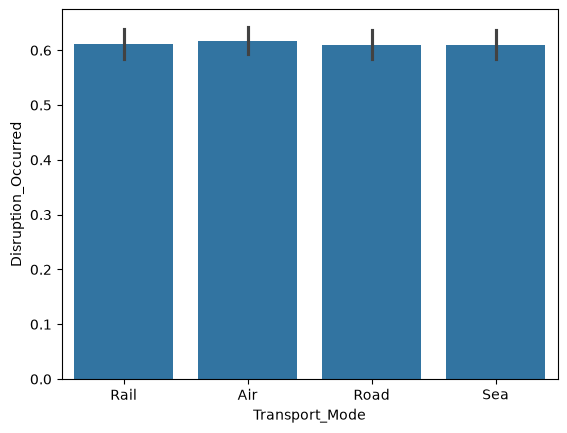

In [17]:
sns.barplot(x='Transport_Mode', y='Disruption_Occurred',data=df)
plt.show()

#### All shipping methods have the same impact on shipment delays.

In [18]:
df.groupby(['Weather_Condition'])['Disruption_Occurred'].mean()

Weather_Condition
Clear        0.369849
Fog          0.480695
Hurricane    1.000000
Rain         0.419652
Storm        0.795409
Name: Disruption_Occurred, dtype: float64

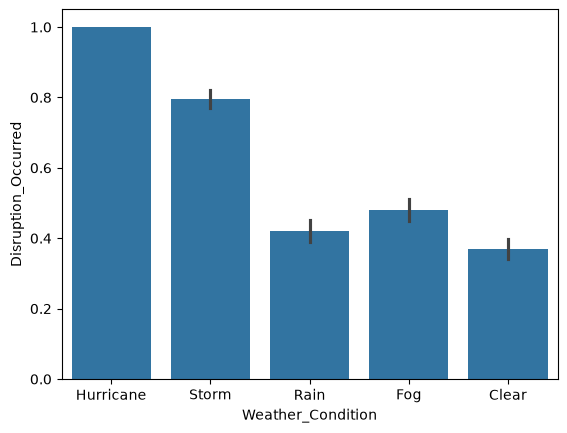

In [19]:
sns.barplot(x='Weather_Condition',y='Disruption_Occurred',data=df)
plt.show()

#### Weather conditions significantly impact shipment delays most notably hurricanes, followed by storms, and then fog.

In [20]:
df.groupby(['Transport_Mode','Weather_Condition'])['Disruption_Occurred'].mean()

Transport_Mode  Weather_Condition
Air             Clear                0.350000
                Fog                  0.500000
                Hurricane            1.000000
                Rain                 0.444000
                Storm                0.788679
Rail            Clear                0.383621
                Fog                  0.456790
                Hurricane            1.000000
                Rain                 0.386957
                Storm                0.821138
Road            Clear                0.377273
                Fog                  0.484252
                Hurricane            1.000000
                Rain                 0.423077
                Storm                0.773663
Sea             Clear                0.371025
                Fog                  0.478599
                Hurricane            1.000000
                Rain                 0.421941
                Storm                0.798387
Name: Disruption_Occurred, dtype: float64

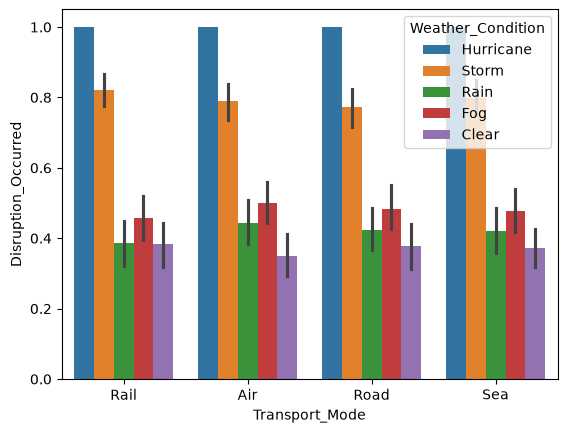

In [21]:
sns.barplot(data=df, x='Transport_Mode', y='Disruption_Occurred', hue='Weather_Condition')
plt.show()

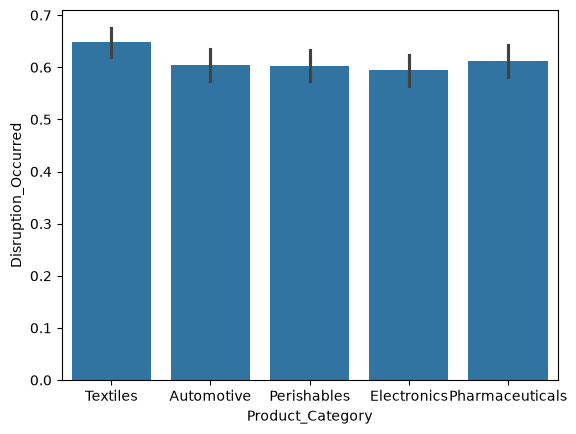

In [22]:
sns.barplot(x='Product_Category',y='Disruption_Occurred',data=df)
plt.show()

#### there are no effict

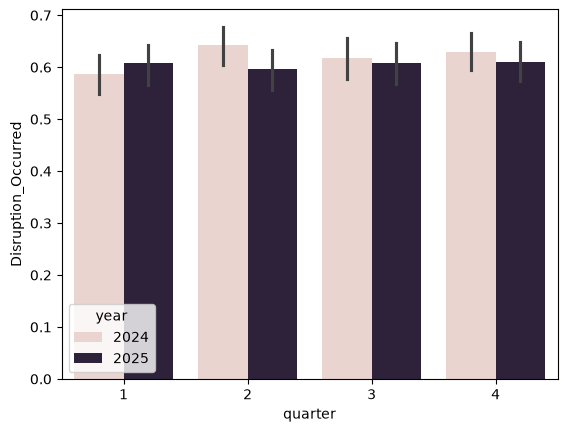

In [23]:
sns.barplot(x='quarter', y='Disruption_Occurred',data=df,hue='year')
plt.show()

#### Quarter and year have no effect on disruption: all values are around 61%

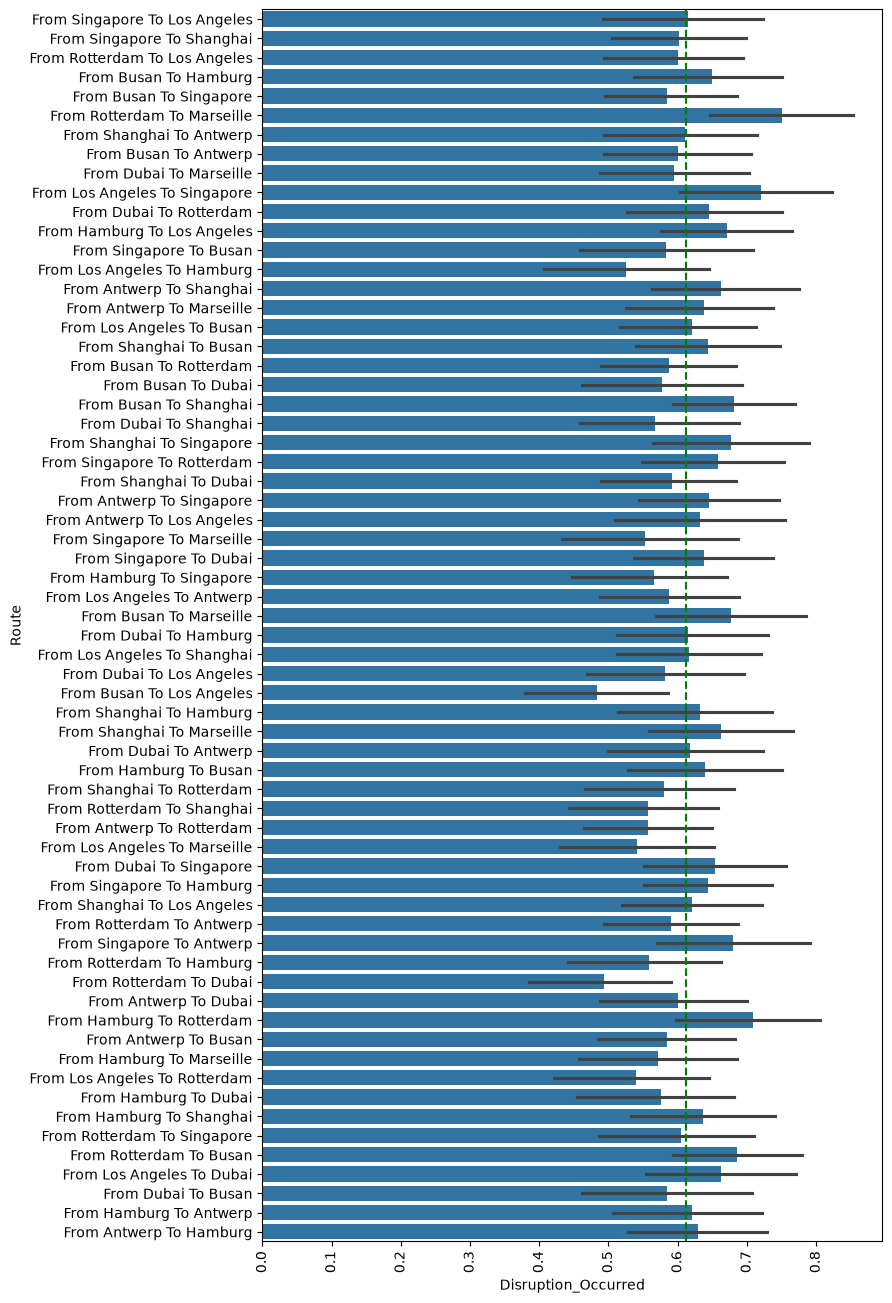

In [24]:
plt.figure(figsize=(8, 16))
sns.barplot(y='Route',x='Disruption_Occurred',data=df)
plt.xticks(rotation=90)
plt.axvline(df['Disruption_Occurred'].mean(), color='green', linestyle='--')
plt.show()

#### Route has no clear effect on disruption: most routes are close to the overall rate (0.6) and the error bars overlap heavily
#### Route may partly reflect distance, so we will check Distance_km directly with a histplot

-----

#### histplot >>> Numeric cols

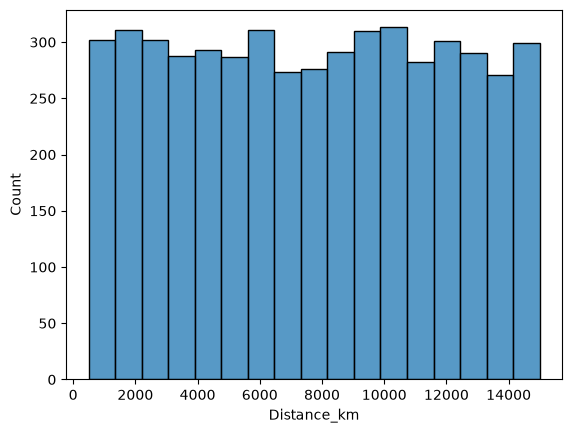

In [25]:
sns.histplot(x='Distance_km',data=df)
plt.show()

In [26]:
df.head()

,Transport_Mode,Product_Category,Distance_km,Weight_MT,Fuel_Price_Index,Geopolitical_Risk_Score,Weather_Condition,Carrier_Reliability_Score,Lead_Time_Days,Disruption_Occurred,Month,year,day_per_week,quarter,Route
0,Rail,Textiles,5930.83,197.42,2.43,5.0,Hurricane,0.865,41.39,1,10,2025,3,4,From Singapore To Los Angeles
1,Rail,Automotive,14285.36,237.24,2.30,7.5,Storm,0.592,40.92,1,4,2024,2,2,From Singapore To Shanghai
2,Rail,Perishables,11113.91,427.42,1.78,5.6,Rain,0.673,11.54,0,1,2024,4,1,From Rotterdam To Los Angeles
3,Rail,Electronics,9180.55,170.66,3.20,0.8,Hurricane,0.832,53.13,1,10,2024,1,4,From Busan To Hamburg
4,Air,Perishables,2762.27,434.96,2.77,1.9,Fog,0.741,0.50,1,9,2024,5,3,From Busan To Singapore


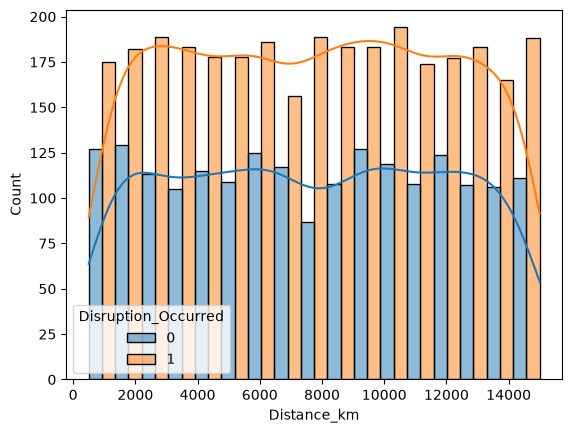

In [27]:
sns.histplot(x='Distance_km',hue='Disruption_Occurred',data=df,multiple='dodge',kde=True)
plt.show()

#### Distance does not affect whether shipments get disrupted, the KDE curves of disrupted and non-disrupted shipments move in parallel across all distances. We saw this using kde=True.

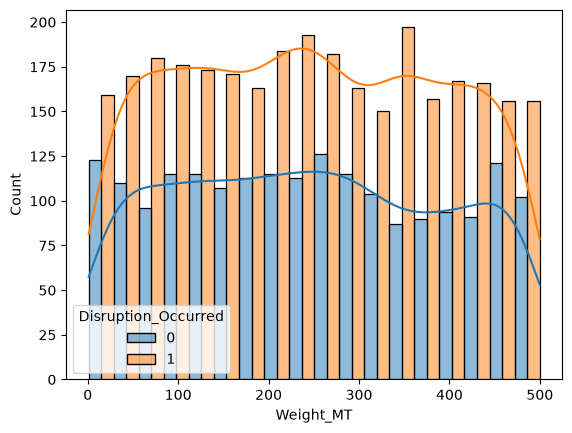

In [28]:
sns.histplot(x='Weight_MT',hue='Disruption_Occurred',data=df,multiple='dodge',kde=True)
plt.show()

#### Weight does not affect

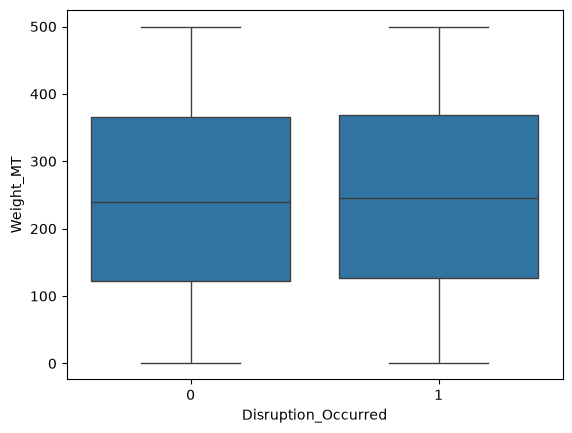

In [29]:
sns.boxplot( x='Disruption_Occurred', y='Weight_MT',data=df)
plt.show()

#### The boxplot shows the same result as the histplot in a clearer way, although I usually use boxplot to detect outliers.

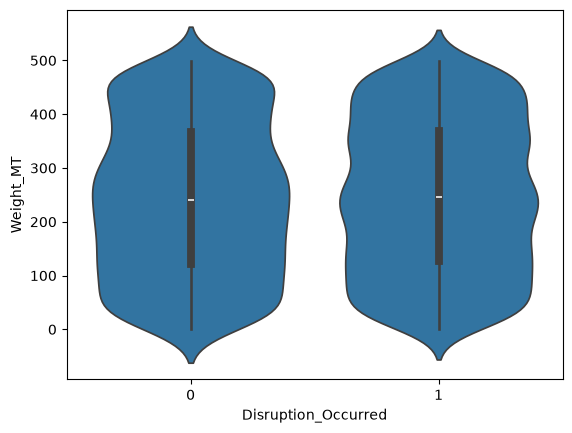

In [30]:
sns.violinplot(x='Disruption_Occurred', y='Weight_MT',data=df)
plt.show()

#### Boxplot + histplot With KDE

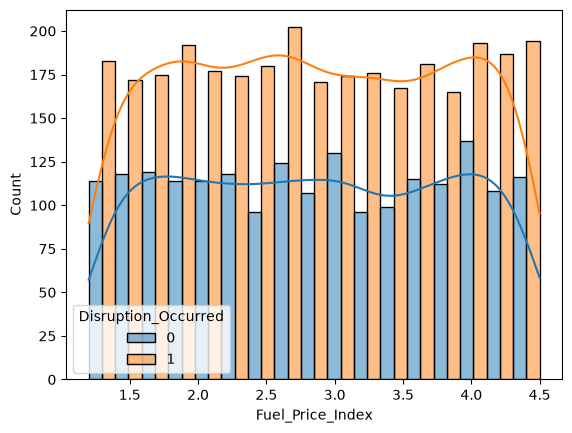

In [31]:
sns.histplot(x='Fuel_Price_Index',hue='Disruption_Occurred' ,data=df,kde=True,multiple='dodge')
plt.show()

<Axes: xlabel='Geopolitical_Risk_Score', ylabel='Count'>

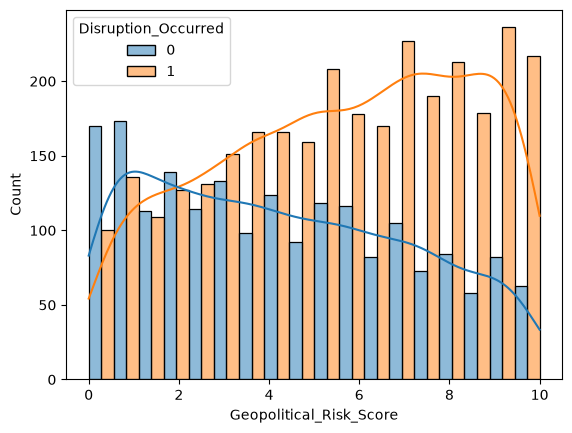

In [32]:
sns.histplot(x='Geopolitical_Risk_Score',hue='Disruption_Occurred' ,data=df,kde=True,multiple='dodge')

#### The higher the geopolitical risk, the more likely a shipment is to be disrupted.

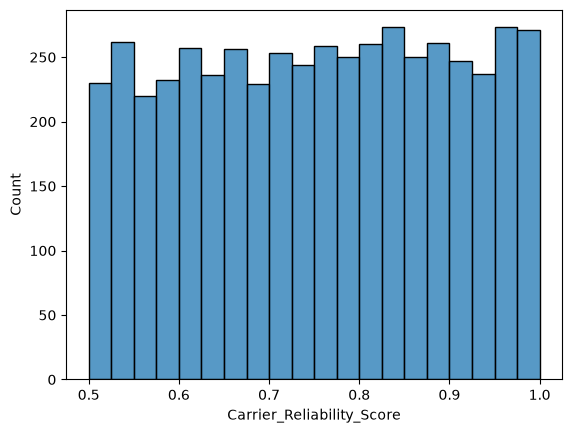

In [33]:
sns.histplot(x='Carrier_Reliability_Score', bins=20,data=df)
plt.show()

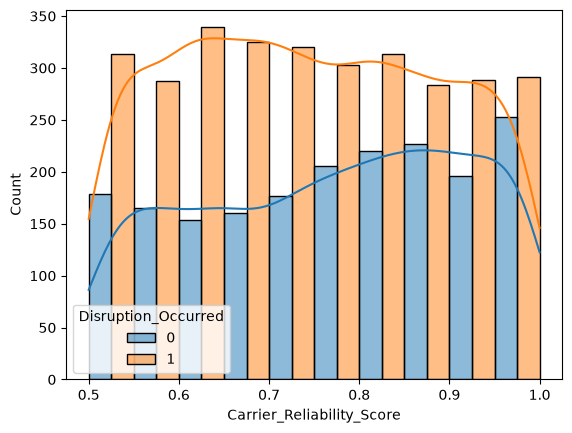

In [34]:
sns.histplot(x='Carrier_Reliability_Score', bins=10,data=df, hue='Disruption_Occurred',multiple='dodge',kde=True)
plt.show()

In [35]:
df.groupby(pd.cut(df['Carrier_Reliability_Score'], bins=5))['Disruption_Occurred'].mean()

Carrier_Reliability_Score
(0.5, 0.6]    0.639498
(0.6, 0.7]    0.675205
(0.7, 0.8]    0.619620
(0.8, 0.9]    0.570201
(0.9, 1.0]    0.564153
Name: Disruption_Occurred, dtype: float64

#### There is an effect, but it is weak.

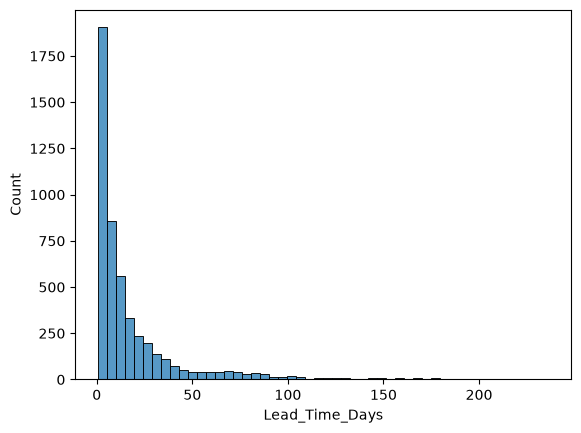

In [36]:
sns.histplot(x='Lead_Time_Days',bins=50,data=df)
plt.show()

In [37]:
df['Lead_Time_Days'].skew().round(2)

np.float64(3.35)

In [38]:
numeric_cols=df.select_dtypes('number').columns
for col in numeric_cols:
    if df[col].skew() > 1 or df[col].skew() < -1:
        print(f'Skew of {col} :  {df[col].skew().round(2)}')

Skew of Lead_Time_Days :  3.35


#### 'Lead_Time_Days' is highly right-skewed (skew = 3.35), far outside the acceptable range (-1 to 1), so we will apply a log transformation

In [39]:
df['Lead_Time_Days']=np.log1p(df['Lead_Time_Days'])

In [40]:
df['Lead_Time_Days'].skew().round(2)

np.float64(0.26)

#### The skew is now 0.26, which is good because it is between -0.5 and 0.5, so the column is fairly symmetric

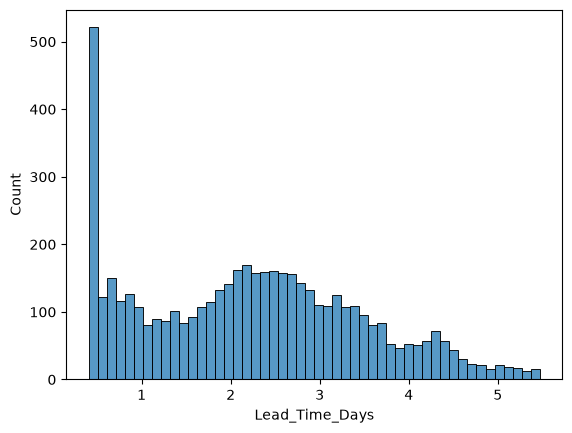

In [41]:
sns.histplot(x='Lead_Time_Days',bins=50,data=df)
plt.show()

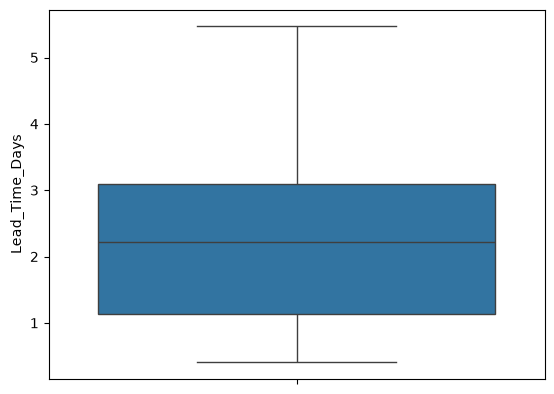

In [42]:
sns.boxplot(y='Lead_Time_Days',data=df)
plt.show()

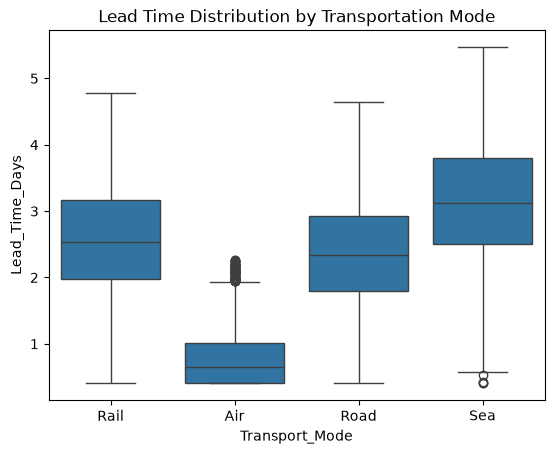

In [43]:
sns.boxplot( x='Transport_Mode', y='Lead_Time_Days', data=df)
plt.title('Lead Time Distribution by Transportation Mode')
plt.show()

#### Air shipments have the shortest lead time by far, Sea shipments have the longest, Rail and Road are in between

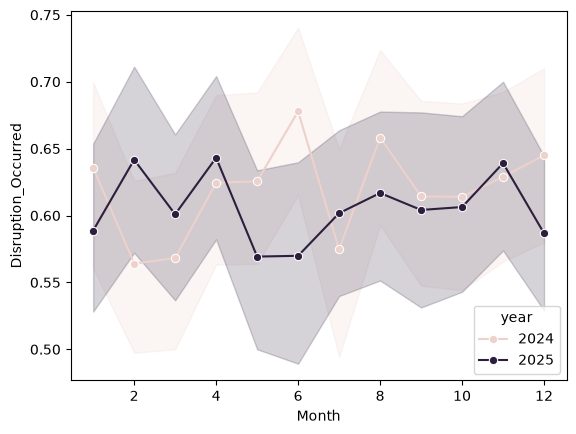

In [44]:
sns.lineplot(x='Month',y='Disruption_Occurred',data=df,hue='year',marker="o")
plt.show()

#### In June 2024, shipping disruptions increased, then decreased in July, and subsequently rose again in August.

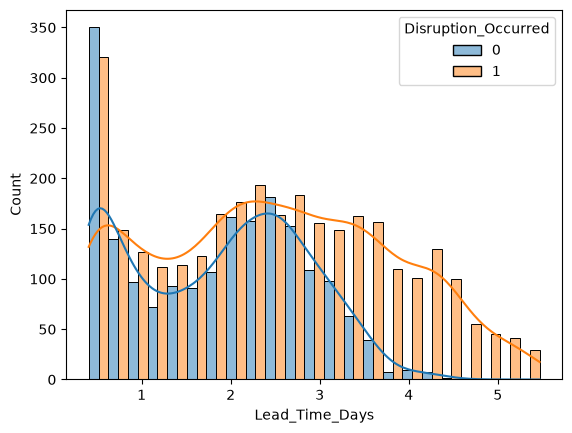

In [45]:
sns.histplot(x='Lead_Time_Days', hue='Disruption_Occurred', data=df, kde=True, multiple='dodge')
plt.show()

#### Long lead times (above 4 in log scale, about 50 days) are almost all disrupted shipments
#### This column must not be included among the training features, as it would lead to data leakage.
#### Data leakage happens when the model is trained on information that would not be available at prediction time. Here, lead time is only known after the shipment arrives, and it is partly a result of the disruption itself.
#### Our goal is to build a model that predicts whether a shipment will be disrupted before it leaves; at that moment, we would not know its total lead time yet.
#### So we drop 'Lead_Time_Days'

In [46]:
df = df.drop(columns='Lead_Time_Days')

In [47]:
X= df.drop(columns='Disruption_Occurred')
y=df['Disruption_Occurred']

In [48]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X,y,stratify=y,test_size=0.2,random_state=42)

In [49]:
print(X_train.shape, X_test.shape, y_train.shape, y_test.shape)

(4000, 13) (1000, 13) (4000,) (1000,)


In [50]:
numeric_cols

Index(['Distance_km', 'Weight_MT', 'Fuel_Price_Index',
       'Geopolitical_Risk_Score', 'Carrier_Reliability_Score',
       'Lead_Time_Days', 'Disruption_Occurred', 'Month', 'year',
       'day_per_week', 'quarter'],
      dtype='str')

In [51]:
num_cols = ['Distance_km', 'Weight_MT', 'Fuel_Price_Index',
            'Geopolitical_Risk_Score', 'Carrier_Reliability_Score',
             'year', 'Month']

cat_cols = ['Transport_Mode', 'Product_Category', 'Weather_Condition', 'Route']

In [52]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler , OneHotEncoder

In [53]:
pros_step = ColumnTransformer([
    ('scalling',StandardScaler(),num_cols),
    ('Encoding',OneHotEncoder(handle_unknown='ignore'),cat_cols)
]
)

In [54]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import ParameterGrid
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, BaggingClassifier
from xgboost import XGBClassifier

In [55]:
neg, pos = (y_train == 0).sum(), (y_train == 1).sum()

models={
    'Logistic_model':LogisticRegression(max_iter=1000, random_state=42, class_weight='balanced'),
    'KNN_model':KNeighborsClassifier(),
    'SVM_model':SVC(probability=True, random_state=42, class_weight='balanced'),
    'DTree_model':DecisionTreeClassifier(random_state=42, class_weight='balanced'),
    'Bagging':BaggingClassifier(estimator=DecisionTreeClassifier(class_weight='balanced'), random_state=42, n_jobs=-1),
    'Random_forest_model':RandomForestClassifier(random_state=42, n_jobs=-1, class_weight='balanced'),
    'XGB':XGBClassifier(random_state=42, n_jobs=-1, scale_pos_weight=neg/pos),
}

In [56]:
params_Grid = {
    'Logistic_model':{
        'model__C':[0.01,0.1,1,10,50],
    },
    'KNN_model':{
        'model__n_neighbors':[3,5,7,11,15,21,31],
        'model__weights':['distance','uniform'],
        'model__metric':['manhattan','euclidean'],
    },
    'SVM_model':[
        {
            'model__kernel':['linear'],
            'model__C':[0.1,1,10,50],
        },
        {
            'model__kernel':['rbf'],
            'model__C':[0.1,1,10,50],
            'model__gamma':['scale',0.01,0.1],
        }
    ],
    'DTree_model':{
        'model__max_depth':[None,3,5,7,10,15],
        'model__min_samples_leaf':[1,5,10,20,30],
    },
    'Bagging':[
        {
            'model__estimator':[DecisionTreeClassifier(random_state=42,class_weight='balanced')],
            'model__estimator__max_depth':[None,5,10],
            'model__estimator__min_samples_leaf':[1,5,10],
            'model__n_estimators':[50,100,200],
            'model__max_samples':[0.5,0.75,1.0],
        },
        {
            'model__estimator':[LogisticRegression(max_iter=1000,random_state=42,class_weight='balanced')],
            'model__estimator__C':[0.1,1,10],
            'model__n_estimators':[50,100],
            'model__max_samples':[0.5,0.75],
        }
    ],
    'Random_forest_model':{
        'model__n_estimators':[100,200,300],
        'model__max_depth':[None,5,10,15],
        'model__min_samples_leaf':[1,5,10],
        'model__max_features':['sqrt',0.5],
        'model__max_samples':[0.5,0.75,None],
    },
    
    'XGB':{
        'model__n_estimators':[50,100,200],
        'model__learning_rate':[0.05,0.1,0.3],
        'model__max_depth':[3,5,7],
        'model__subsample':[0.8,1.0],
        'model__colsample_bytree':[0.8,1.0],
        'model__min_child_weight':[1,5],
        'model__reg_lambda':[1,10],
    },

}

In [57]:
from sklearn.metrics import accuracy_score,f1_score,precision_score,recall_score,roc_auc_score,average_precision_score

In [58]:
Grid_search={}
scores=[]
for name,grid in params_Grid.items():
    pipe = Pipeline([
        ('preprocessing', pros_step),
        ('model', models[name])
    ])
    search= GridSearchCV(pipe,grid,cv=5,scoring='roc_auc',n_jobs=-1)
    search.fit(X_train,y_train)
    Grid_search[name]=search
    best_CV= search.best_estimator_
    y_train_pred = best_CV.predict(X_train)
    y_test_pred = best_CV.predict(X_test)
    y_test_prop =best_CV.predict_proba(X_test)[:,1]

    scores.append({
        'Model':name,
        'CV ROC-AUC':search.best_score_,
        'Accuracy Train':accuracy_score(y_train,y_train_pred),
        'Accuracy Test':accuracy_score(y_test,y_test_pred),
        'Precision':precision_score(y_test,y_test_pred),
        'Recall Train':recall_score(y_train,y_train_pred),
        'Recall Test':recall_score(y_test,y_test_pred),
        'F1 Train':f1_score(y_train,y_train_pred),
        'F1 Test':f1_score(y_test,y_test_pred),
        'ROC-AUC':roc_auc_score(y_test,y_test_prop),
        'PR-AUC':average_precision_score(y_test,y_test_prop),
    })
results_df = (
    pd.DataFrame(scores)
    .sort_values('CV ROC-AUC', ascending=False)
    .reset_index(drop=True)
)
results_df

c:\Users\amroa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


,Model,CV ROC-AUC,Accuracy Train,Accuracy Test,Precision,Recall Train,Recall Test,F1 Train,F1 Test,ROC-AUC,PR-AUC
0,XGB,0.828874,0.71400,0.711,0.900990,0.595102,0.593801,0.718227,0.715831,0.820007,0.896353
1,Bagging,0.828428,0.73750,0.740,0.858012,0.693878,0.690049,0.764045,0.764919,0.829070,0.902221
2,Random_forest_model,0.828382,0.72125,0.704,0.901266,0.600000,0.580750,0.725031,0.706349,0.821756,0.897174
3,Logistic_model,0.827101,0.74150,0.738,0.863354,0.688980,0.680261,0.765533,0.760949,0.828867,0.902109
4,SVM_model,0.821896,0.72525,0.727,0.895349,0.622041,0.628059,0.734989,0.738255,0.818923,0.892891
5,DTree_model,0.817837,0.73650,0.714,0.817476,0.680408,0.686786,0.759799,0.746454,0.812244,0.878759
6,KNN_model,0.800934,1.00000,0.705,0.724576,1.000000,0.836868,1.000000,0.776684,0.788097,0.874876


###### The recall results are extremely poor.

In [ ]:
best_bag = Grid_search['Bagging'].best_estimator_
y_prob = best_bag.predict_proba(X_test)[:, 1]
y_prob_train = best_bag.predict_proba(X_train)[:, 1]

In [69]:
for_threshold = []
for threshold in [0.5, 0.45, 0.4, 0.35, 0.3]:
    y_train_t = (y_prob_train >= threshold).astype(int)
    y_test_t  = (y_prob >= threshold).astype(int)
    for_threshold .append({
        'Threshold':threshold,
        'Accuracy Train':accuracy_score(y_train, y_train_t),
        'Accuracy Test':accuracy_score(y_test, y_test_t),
        'Precision':precision_score(y_test, y_test_t),
        'Recall Train':recall_score(y_train, y_train_t),
        'Recall Test':recall_score(y_test, y_test_t),
        'F1 Train':f1_score(y_train, y_train_t),
        'F1 Test':f1_score(y_test, y_test_t),
        'ROC-AUC':roc_auc_score(y_test, y_prob),
        'PR-AUC':average_precision_score(y_test, y_prob),
    })

pd.DataFrame(for_threshold)

,Threshold,Accuracy Train,Accuracy Test,Precision,Recall Train,Recall Test,F1 Train,F1 Test,ROC-AUC,PR-AUC
0,0.50,0.73750,0.740,0.858012,0.693878,0.690049,0.764045,0.764919,0.82907,0.902221
1,0.45,0.74475,0.749,0.819788,0.751429,0.756933,0.782905,0.787108,0.82907,0.902221
2,0.40,0.74700,0.729,0.767188,0.805714,0.800979,0.795968,0.783719,0.82907,0.902221
3,0.35,0.74200,0.732,0.747489,0.852653,0.849918,0.801919,0.795420,0.82907,0.902221
4,0.30,0.73225,0.704,0.703466,0.895918,0.893964,0.803882,0.787356,0.82907,0.902221


#### I chose a threshold of 0.40 because it gives the best balance between Precision (0.77) and Recall (0.80)
#### Compared to the default 0.50, Recall increased from 0.69 to 0.80, while Precision dropped from 0.86 to 0.77

In [63]:
Grid_search['Bagging'].best_params_

{'model__estimator': LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42),
 'model__estimator__C': 0.1,
 'model__max_samples': 0.5,
 'model__n_estimators': 100}

#### The best Bagging model uses 100 Logistic Regression models (C=0.1), each trained on 50% of the data


In [65]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

In [66]:
y_final = (y_prob >= 0.4).astype(int)
print(classification_report(y_test, y_final))

              precision    recall  f1-score   support

           0       0.66      0.61      0.64       387
           1       0.77      0.80      0.78       613

    accuracy                           0.73      1000
   macro avg       0.71      0.71      0.71      1000
weighted avg       0.73      0.73      0.73      1000



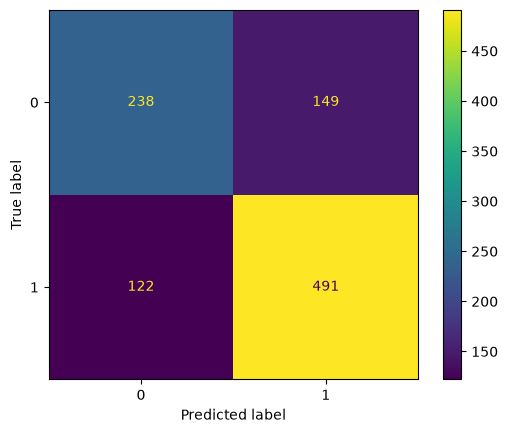

In [67]:
ConfusionMatrixDisplay(confusion_matrix(y_test, y_final)).plot()
plt.show()

#### The model caught 491 of 613 disrupted shipments (Recall = 0.80) and missed 122
#### The main weakness is false alarms: 149 of 387 safe shipments were flagged as disrupted
#### This trade-off is acceptable because missing a disruption costs more than a false alarm

In [ ]:
from sklearn.model_selection import FixedThresholdClassifier


In [75]:
final_model = FixedThresholdClassifier(best_bag, threshold=0.4)
final_model.fit(X, y)

,"estimator estimator: estimator instanceThe binary classifier, fitted or not, for which we want to optimizethe decision threshold used during `predict`.",Pipeline(step...m_state=42))])
,"threshold threshold: {""auto""} or float, default=""auto""The decision threshold to use when converting posterior probability estimates(i.e. output of `predict_proba`) or decision scores (i.e. output of`decision_function`) into a class label. When `""auto""`, the threshold is setto 0.5 if `predict_proba` is used as `response_method`, otherwise it is set to0 (i.e. the default threshold for `decision_function`).",0.4
,"pos_label pos_label: int, float, bool or str, default=NoneThe label of the positive class. Used to process the output of the`response_method` method. When `pos_label=None`, if `y_true` is in `{-1, 1}` or`{0, 1}`, `pos_label` is set to 1, otherwise an error will be raised.",None
,"response_method response_method: {""auto"", ""decision_function"", ""predict_proba""}, default=""auto""Methods by the classifier `estimator` corresponding to thedecision function for which we want to find a threshold. It can be:* if `""auto""`, it will try to invoke `""predict_proba""` or `""decision_function""` in that order.* otherwise, one of `""predict_proba""` or `""decision_function""`. If the method is not implemented by the classifier, it will raise an error.",'auto'
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The class labels.","ndarray[int64](2,)","[0,1]"
estimator_ estimator_: estimator instanceThe fitted classifier used when predicting.,Pipeline,Pipeline(step...m_state=42))])
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit.","ndarray[object](13,)","['Transport_Mode','Product_Category','Distance_km',...,'day_per_week', 'quarter','Route']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit.,int,13
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('scalling', ...), ('Encoding', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` a